EDA, evaluation, visualizations

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Загружаем датасет
df = pd.read_csv("../data/StudentsPerformance.csv")

# Показываем первые 5 строк
display(df.head())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [9]:
# Размер таблицы
print("Размер датасета:", df.shape)

# Названия колонок
print("\nКолонки:")
print(df.columns.tolist())

# Типы данных и пропущенные значения
print("\nИнформация о данных:")
df.info()

# Количество пропущенных значений
print("\nПропущенные значения:")
print(df.isnull().sum())

Размер датасета: (1000, 8)

Колонки:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Пропущенные значения:
gender                         0
race/ethnicity 

In [10]:
# Считаем средний балл по трём экзаменам
df["average_score"] = (
    df["math score"]
    + df["reading score"]
    + df["writing score"]
) / 3

# Pass = 1, если средний балл строго больше 60
# Fail = 0, если средний балл меньше или равен 60
df["final_grade"] = (
    df["average_score"] > 60
).astype(int)

# Посмотрим результат
display(
    df[
        [
            "math score",
            "reading score",
            "writing score",
            "average_score",
            "final_grade"
        ]
    ].head(10)
)

,math score,reading score,writing score,average_score,final_grade
0,72,72,74,72.666667,1
1,69,90,88,82.333333,1
2,90,95,93,92.666667,1
3,47,57,44,49.333333,0
4,76,78,75,76.333333,1
5,71,83,78,77.333333,1
6,88,95,92,91.666667,1
7,40,43,39,40.666667,0
8,64,64,67,65.000000,1
9,38,60,50,49.333333,0


final_grade
0    293
1    707
Name: count, dtype: int64
final_grade
0    29.3
1    70.7
Name: proportion, dtype: float64


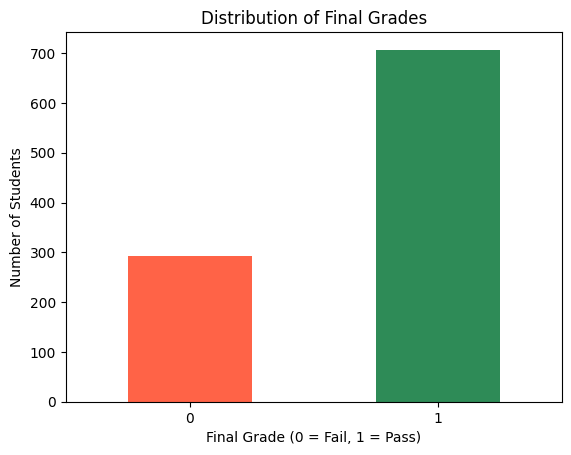

In [11]:
# Количество студентов в каждом классе
print(df["final_grade"].value_counts().sort_index())

# Доли классов в процентах
print(
    df["final_grade"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

# Строим график
df["final_grade"].value_counts().sort_index().plot(
    kind="bar",
    color=["tomato", "seagreen"]
)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

In [12]:
# Признаки, по которым будет работать модель
X = df[
    [
        "gender",
        "race/ethnicity",
        "parental level of education",
        "lunch",
        "test preparation course"
    ]
].copy()

# Правильные ответы, которые модель должна научиться предсказывать
y = df["final_grade"].copy()

print("Размер X:", X.shape)
print("Размер y:", y.shape)

display(X.head())
print(y.head())

Размер X: (1000, 5)
Размер y: (1000,)


,gender,race/ethnicity,parental level of education,lunch,test preparation course
0,female,group B,bachelor's degree,standard,none
1,female,group C,some college,standard,completed
2,female,group B,master's degree,standard,none
3,male,group A,associate's degree,free/reduced,none
4,male,group C,some college,standard,none


0    1
1    1
2    1
3    0
4    1
Name: final_grade, dtype: int64


In [13]:
# Разделяем данные на train и test
# Реализуем разделение самостоятельно, без scikit-learn

rng = np.random.default_rng(42)

indices = rng.permutation(len(X))
split_index = int(len(X) * 0.8)

train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (800, 5) (800,)
Test: (200, 5) (200,)


In [14]:
# Создаём словари категорий только по обучающей выборке
encoders = {}

for column in X_train.columns:
    categories = sorted(X_train[column].dropna().unique())
    encoders[column] = {
        category: code
        for code, category in enumerate(categories)
    }

    # Применяем словарь к train и test
    X_train[column] = X_train[column].map(encoders[column])
    X_test[column] = X_test[column].map(encoders[column])

print("Закодированные данные:")
display(X_train.head())

print("\nСловари кодирования:")
print(encoders)

Закодированные данные:


,gender,race/ethnicity,parental level of education,lunch,test preparation course
978,1,3,2,1,0
933,1,2,1,0,0
859,1,2,0,0,1
916,1,4,1,1,0
127,1,3,4,1,0



Словари кодирования:
{'gender': {'female': 0, 'male': 1}, 'race/ethnicity': {'group A': 0, 'group B': 1, 'group C': 2, 'group D': 3, 'group E': 4}, 'parental level of education': {"associate's degree": 0, "bachelor's degree": 1, 'high school': 2, "master's degree": 3, 'some college': 4, 'some high school': 5}, 'lunch': {'free/reduced': 0, 'standard': 1}, 'test preparation course': {'completed': 0, 'none': 1}}


In [ ]:
print("Количество строк в обучении:", len(X_train))
print("Количество строк в тесте:", len(X_test))

print("\nКлассы в обучающей выборке:")
print(y_train.value_counts().sort_index())

print("\nКлассы в тестовой выборке:")
print(y_test.value_counts().sort_index())

print("\nПропуски в X_train:")
print(X_train.isnull().sum())

print("\nПропуски в X_test:")
print(X_test.isnull().sum())